In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("..") / "DATA" / "PROCESSED"
df = pd.read_csv(DATA / "arxiv_abstracts_sample.csv.gz", dtype={"id": str})
df.head()

,id,title,abstract,authors,author_count,categories,primary_category,category_count,field,comments,journal_ref,doi,license,first_version_date,version_count,label
0,2303.00306,A massive interacting galaxy 510 million years...,JWST observations confirm the existence of gal...,"Kristan Boyett, Michele Trenti, Nicha Leethoch...",27,astro-ph.GA,astro-ph.GA,1,astrophysics,"52 pages, 10 figures This version of the artic...",NaN,NaN,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,2,post_chatgpt
1,2303.00410,JWST/NIRSpec Measurements of the Relationships...,We analyze the rest-optical emission-line rati...,"Alice E. Shapley, Naveen A. Reddy, Ryan L. San...",5,astro-ph.GA,astro-ph.GA,1,astrophysics,"10 pages, 4 figures, ApJL, in press",NaN,10.3847/2041-8213/acd939,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,2,post_chatgpt
2,2303.00489,The miniJPAS survey quasar selection II: Machi...,Astrophysical surveys rely heavily on the clas...,"Nat\'alia V.N. Rodrigues, L. Raul Abramo, Caro...",26,astro-ph.GA astro-ph.CO,astro-ph.GA,2,astrophysics,"16 pages, 15 figures, published by MNRAS",Monthly Notices of the Royal Astronomical Soci...,10.1093/mnras/stac2836,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,1,post_chatgpt
3,2303.00584,A Search for Chemical Anomalies of Seven A-typ...,We present a chemical abundance analysis of se...,Yahya Nasolo and \c{S}eyma \c{C}al{\i}\c{s}kan,2,astro-ph.SR,astro-ph.SR,1,astrophysics,NaN,NaN,10.1093/mnras/stad662,http://creativecommons.org/licenses/by/4.0/,2023-03-01,1,post_chatgpt
4,2303.00603,Radio jet precession in M81*,We report four novel position angle measuremen...,"S.D. von Fellenberg, M. Janssen, J. Davelaar, ...",8,astro-ph.HE astro-ph.GA,astro-ph.HE,2,astrophysics,NaN,"A&A 672, L5 (2023)",10.1051/0004-6361/202245506,http://creativecommons.org/licenses/by/4.0/,2023-03-01,1,post_chatgpt


# Exploratory Data Analysis of `df`

1. Structure and data quality
2. Label and field balance
3. Numeric features
4. Time trends
5. Categories
6. Metadata completeness and licenses
7. Text length
8. Authors
9. Vocabulary
10. Correlations

## 1. Structure and data quality

In [2]:
import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 100

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.info()
display(df.describe(include="all").T)

Shape: 60,000 rows x 16 columns
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id                  60000 non-null  str  
 1   title               60000 non-null  str  
 2   abstract            60000 non-null  str  
 3   authors             60000 non-null  str  
 4   author_count        60000 non-null  int64
 5   categories          60000 non-null  str  
 6   primary_category    60000 non-null  str  
 7   category_count      60000 non-null  int64
 8   field               60000 non-null  str  
 9   comments            43695 non-null  str  
 10  journal_ref         9825 non-null   str  
 11  doi                 17643 non-null  str  
 12  license             60000 non-null  str  
 13  first_version_date  60000 non-null  str  
 14  version_count       60000 non-null  int64
 15  label               60000 non-null  str  
dtypes: int64(3), str(13

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,60000,60000,2303.00306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,60000,59998,BERTnesia: Investigating the capture and forgetting of knowledge in BERT,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
abstract,60000,59999,This paper introduces the task of factual error correction: performing edits...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
authors,60000,58288,John Southworth,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
author_count,60000.0,NaN,NaN,NaN,6.200067,25.082113,1.0,2.0,3.0,6.0,1835.0
categories,60000,3745,cs.CL,9595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
primary_category,60000,37,cs.CL,20000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_count,60000.0,NaN,NaN,NaN,1.710433,0.896622,1.0,1.0,1.0,2.0,9.0
field,60000,3,astrophysics,20000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comments,43695,32099,10 pages,180,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
display(miss.sort_values("pct", ascending=False))

print("Duplicate rows:     ", df.duplicated().sum())
print("Duplicate ids:      ", df["id"].duplicated().sum())
print("Duplicate titles:   ", df["title"].duplicated().sum())
print("Duplicate abstracts:", df["abstract"].duplicated().sum())

,missing,pct
journal_ref,50175,83.62
doi,42357,70.60
comments,16305,27.18
id,0,0.00
author_count,0,0.00
title,0,0.00
abstract,0,0.00
authors,0,0.00
category_count,0,0.00
primary_category,0,0.00


Duplicate rows:      0
Duplicate ids:       0
Duplicate titles:    2
Duplicate abstracts: 1


## 2. Label and field balance

,n,pct
label,,
post_chatgpt,30000,50.0
pre_chatgpt,30000,50.0


label,post_chatgpt,pre_chatgpt,All
field,,,
astrophysics,10000,10000,20000
computational_linguistics,10000,10000,20000
math,10000,10000,20000
All,30000,30000,60000


label,post_chatgpt,pre_chatgpt
field,,
astrophysics,33.3,33.3
computational_linguistics,33.3,33.3
math,33.3,33.3


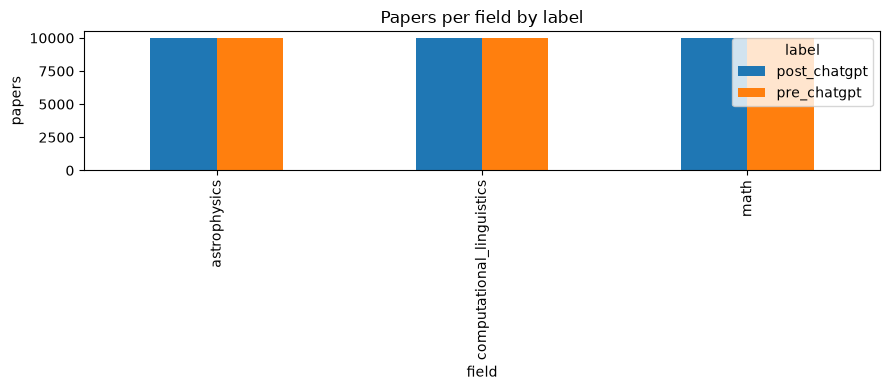

In [4]:
lab = df["label"].value_counts(dropna=False).to_frame("n")
lab["pct"] = (lab["n"] / lab["n"].sum() * 100).round(2)
display(lab)

ct = pd.crosstab(df["field"], df["label"])
display(pd.crosstab(df["field"], df["label"], margins=True))
display(pd.crosstab(df["field"], df["label"], normalize="columns").mul(100).round(1))

ct.plot(kind="bar", figsize=(9, 4), title="Papers per field by label")
plt.ylabel("papers")
plt.tight_layout()
plt.show()

## 3. Numeric features

,count,mean,std,min,50%,90%,99%,max
author_count,60000.0,6.200067,25.082113,1.0,3.0,10.0,49.0,1835.0
category_count,60000.0,1.710433,0.896622,1.0,1.0,3.0,5.0,9.0
version_count,60000.0,1.585550,0.926640,1.0,1.0,3.0,5.0,27.0


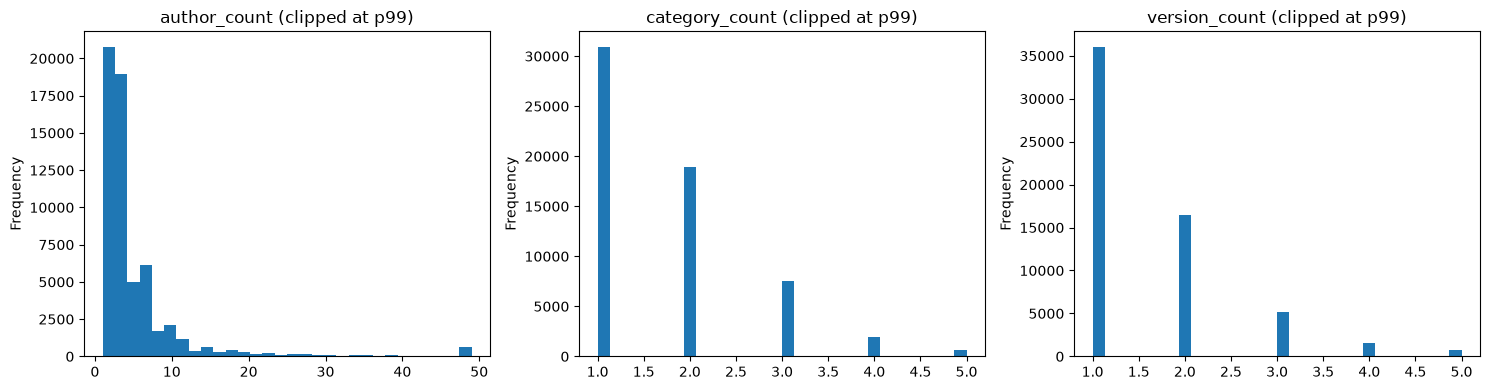

author_count        category_count        version_count       
                     mean median           mean median          mean median
label                                                                      
post_chatgpt         6.53    3.0           1.73    1.0          1.55    1.0
pre_chatgpt          5.87    3.0           1.69    1.0          1.62    1.0

author_count        category_count         \
                                  mean median           mean median   
field                                                                 
astrophysics                     11.35    5.0           1.64    1.0   
computational_linguistics         5.03    4.0           1.76    2.0   
math                              2.22    2.0           1.73    1.0   

                          version_count         
                                   mean median  
field                                           
astrophysics                       1.45    1.0  
computational_linguistics          1.61    1.0  
math                               1.70    1.0

In [5]:
num_cols = ["author_count", "category_count", "version_count"]
display(df[num_cols].describe(percentiles=[0.5, 0.9, 0.99]).T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    df[c].clip(upper=df[c].quantile(0.99)).plot.hist(bins=30, ax=ax, title=f"{c} (clipped at p99)")
plt.tight_layout()
plt.show()

display(df.groupby("label")[num_cols].agg(["mean", "median"]).round(2))
display(df.groupby("field")[num_cols].agg(["mean", "median"]).round(2))

## 4. Time trends

Unparseable dates: 0


,min,max,count
label,,,
post_chatgpt,2023-03-01,2026-10-29,30000
pre_chatgpt,2019-01-01,2022-11-29,30000


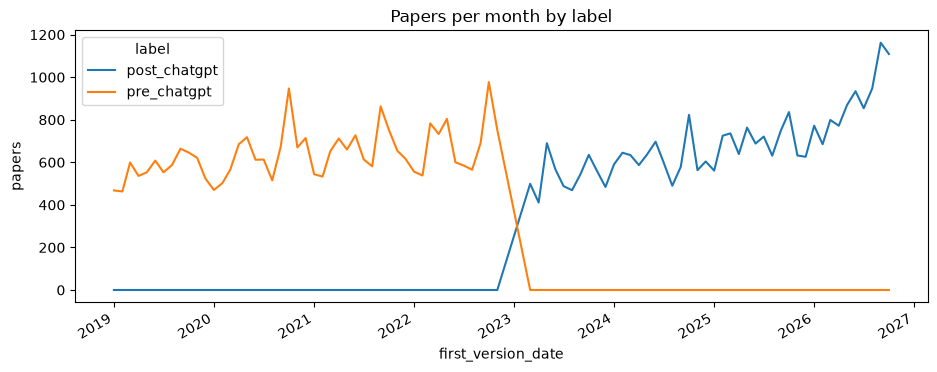

field,astrophysics,computational_linguistics,math
first_version_date,,,
2025-11,235,169,228
2025-12,253,157,216
2026-01,245,275,252
2026-02,226,240,219
2026-03,269,264,266
2026-04,241,285,246
2026-05,265,350,254
2026-06,303,338,293
2026-07,340,219,295


In [6]:
df["first_version_date"] = pd.to_datetime(df["first_version_date"], errors="coerce")
print("Unparseable dates:", df["first_version_date"].isna().sum())
display(df.groupby("label")["first_version_date"].agg(["min", "max", "count"]))

monthly = (
    df.dropna(subset=["first_version_date"])
    .groupby([pd.Grouper(key="first_version_date", freq="MS"), "label"])
    .size()
    .unstack(fill_value=0)
)
monthly.plot(figsize=(11, 4), title="Papers per month by label")
plt.ylabel("papers")
plt.show()

display(df.groupby([df["first_version_date"].dt.to_period("M"), "field"]).size().unstack(fill_value=0).tail(12))

## 5. Categories

Unique primary categories: 37


,n
primary_category,
cs.CL,20000
astro-ph.GA,5226
astro-ph.HE,4170
astro-ph.SR,3430
astro-ph.CO,2772
astro-ph.EP,2456
math.AP,2301
math.CO,2054
astro-ph.IM,1946


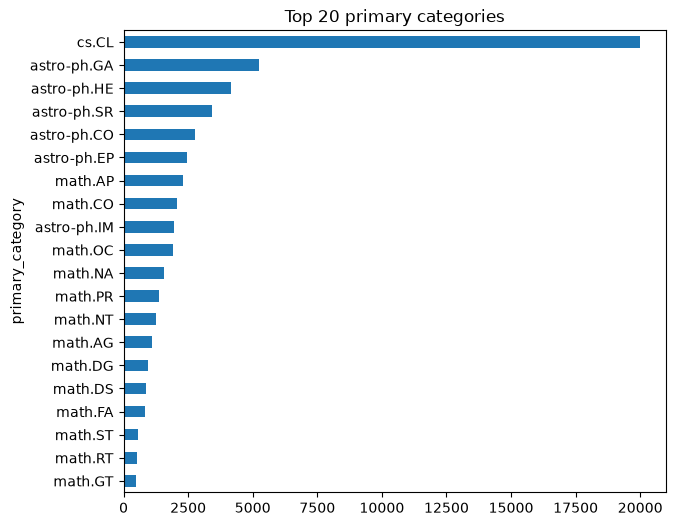

Unique categories (incl. cross-lists): 151


,n
categories,
cs.CL,20003
astro-ph.GA,7342
cs.AI,6133
astro-ph.HE,5254
astro-ph.SR,5222
cs.LG,4753
astro-ph.CO,3709
astro-ph.IM,3223
astro-ph.EP,3171


label,post_chatgpt,pre_chatgpt,total
primary_category,,,
cs.CL,10000,10000,20000
astro-ph.GA,2641,2585,5226
astro-ph.HE,2089,2081,4170
astro-ph.SR,1638,1792,3430
astro-ph.CO,1422,1350,2772
astro-ph.EP,1218,1238,2456
math.AP,1124,1177,2301
math.CO,1062,992,2054
astro-ph.IM,992,954,1946


In [7]:
print("Unique primary categories:", df["primary_category"].nunique())
top_prim = df["primary_category"].value_counts().head(20)
display(top_prim.to_frame("n"))
top_prim.sort_values().plot.barh(figsize=(7, 6), title="Top 20 primary categories")
plt.show()

all_cats = df["categories"].dropna().str.split().explode()
print("Unique categories (incl. cross-lists):", all_cats.nunique())
display(all_cats.value_counts().head(20).to_frame("n"))

prim_label = pd.crosstab(df["primary_category"], df["label"])
prim_label["total"] = prim_label.sum(axis=1)
display(prim_label.sort_values("total", ascending=False).head(20))

## 6. Metadata completeness and licenses

In [8]:
has = pd.DataFrame({f"has_{c}": df[c].notna() for c in ["comments", "journal_ref", "doi"]})
display(has.groupby(df["label"]).mean().mul(100).round(1))
display(has.groupby(df["field"]).mean().mul(100).round(1))

display(df["license"].value_counts(dropna=False).to_frame("n"))
display(pd.crosstab(df["license"].fillna("missing"), df["label"]))

,has_comments,has_journal_ref,has_doi
label,,,
post_chatgpt,69.7,13.4,18.6
pre_chatgpt,76.0,19.4,40.2


,has_comments,has_journal_ref,has_doi
field,,,
astrophysics,91.5,29.0,64.0
computational_linguistics,65.6,6.8,7.6
math,61.4,13.3,16.6


,n
license,
http://arxiv.org/licenses/nonexclusive-distrib/1.0/,33534
http://creativecommons.org/licenses/by/4.0/,20038
http://creativecommons.org/licenses/by-nc-nd/4.0/,2320
http://creativecommons.org/licenses/by-nc-sa/4.0/,2145
http://creativecommons.org/licenses/by-sa/4.0/,1236
http://creativecommons.org/publicdomain/zero/1.0/,727


label,post_chatgpt,pre_chatgpt
license,,
http://arxiv.org/licenses/nonexclusive-distrib/1.0/,12688,20846
http://creativecommons.org/licenses/by-nc-nd/4.0/,1480,840
http://creativecommons.org/licenses/by-nc-sa/4.0/,1296,849
http://creativecommons.org/licenses/by-sa/4.0/,728,508
http://creativecommons.org/licenses/by/4.0/,13412,6626
http://creativecommons.org/publicdomain/zero/1.0/,396,331


## 7. Text length

,count,mean,std,min,1%,50%,99%,max
title_words,60000.0,10.516700,3.871159,1.0,3.0,10.0,22.0,37.0
abstract_words,60000.0,162.226483,64.991799,7.0,29.0,161.0,296.0,672.0
abstract_chars,60000.0,1117.280633,441.938721,45.0,195.0,1123.0,1914.0,4432.0


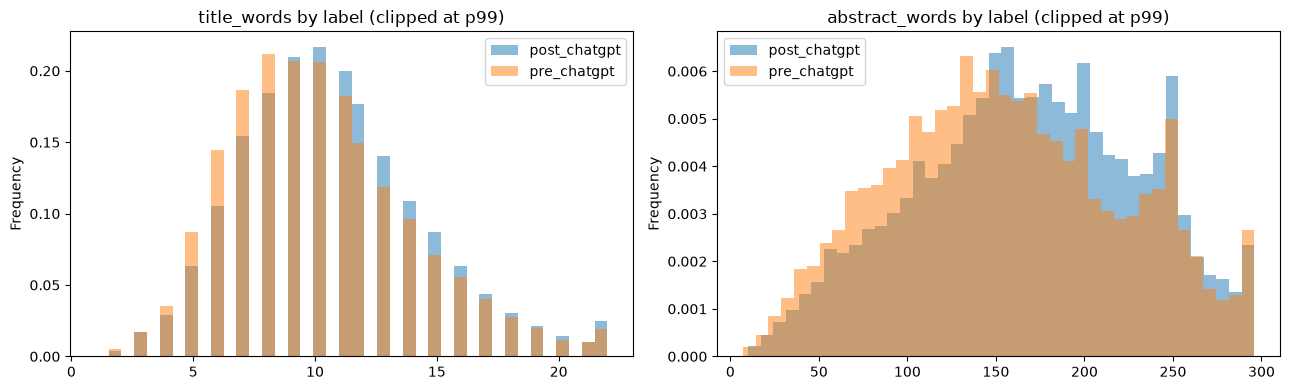

title_words        abstract_words        abstract_chars        
                    mean median           mean median           mean  median
label                                                                       
post_chatgpt        10.8   10.0          167.9  169.0         1178.2  1206.0
pre_chatgpt         10.3   10.0          156.6  153.0         1056.4  1046.0

title_words        abstract_words         \
                                 mean median           mean median   
field                                                                
astrophysics                     12.4   12.0          210.0  219.0   
computational_linguistics         9.9   10.0          161.9  159.0   
math                              9.3    9.0          114.8  106.0   

                          abstract_chars          
                                    mean  median  
field                                             
astrophysics                      1406.6  1465.0  
computational_linguistics         1157.6  1140.0  
math                               787.7   720.0

Abstracts under 30 words: 612


In [9]:
df["title_words"] = df["title"].fillna("").str.split().str.len()
df["abstract_words"] = df["abstract"].fillna("").str.split().str.len()
df["abstract_chars"] = df["abstract"].fillna("").str.len()
text_cols = ["title_words", "abstract_words", "abstract_chars"]
display(df[text_cols].describe(percentiles=[0.01, 0.5, 0.99]).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["title_words", "abstract_words"]):
    for lbl, g in df.groupby("label"):
        g[c].clip(upper=df[c].quantile(0.99)).plot.hist(bins=40, alpha=0.5, density=True, ax=ax, label=lbl)
    ax.set_title(f"{c} by label (clipped at p99)")
    ax.legend()
plt.tight_layout()
plt.show()

display(df.groupby("label")[text_cols].agg(["mean", "median"]).round(1))
display(df.groupby("field")[text_cols].agg(["mean", "median"]).round(1))
print("Abstracts under 30 words:", (df["abstract_words"] < 30).sum())

## 8. Authors

In [10]:
authors = df["authors"].dropna().str.split(r",\s*|\s+and\s+").explode().str.strip()
authors = authors[authors != ""]
print("Author mentions:", len(authors), "| unique names:", authors.nunique())
display(authors.value_counts().head(15).to_frame("papers"))

print("Single-author papers (%):", round((df["author_count"] == 1).mean() * 100, 1))
display(df.nlargest(5, "author_count")[["id", "title", "author_count", "field"]])

Author mentions: 408270 | unique names: 188500


,papers
authors,
Italy,1079
Spain,587
France,552
USA,538
2),507
UK,366
Germany,360
CNRS,339
Astronomy,325


Single-author papers (%): 14.1


,id,title,author_count,field
8243,2605.05444,Searches for Binary Mergers with Sub-solar Mass Components in Data from the ...,1835,astrophysics
4384,2501.01495,Search for continuous gravitational waves from known pulsars in the first pa...,1819,astrophysics
17425,2111.15507,All-sky search for gravitational wave emission from scalar boson clouds arou...,1672,astrophysics
17230,2111.03608,Search for Gravitational Waves Associated with Gamma-Ray Bursts Detected by ...,1635,astrophysics
15921,2104.14417,Constraints from LIGO O3 data on gravitational-wave emission due to r-modes ...,1599,astrophysics


## 9. Vocabulary

In [11]:
stop = set("""a an the and or of in on for to with by from at as is are was were be been this that these those it its we our
which can has have had not but also than then such using used use based via into over under between both more most
their they there here how what when where who whom while however paper results show shown study new two one""".split())

def tokens(s):
    return [w for w in re.findall(r"[a-z][a-z\-]{2,}", s.lower()) if w not in stop]

counts = {lbl: Counter(w for s in g["abstract"].dropna() for w in tokens(s)) for lbl, g in df.groupby("label")}
display(pd.DataFrame({lbl: pd.Series(dict(c.most_common(20))).index for lbl, c in counts.items()}))

# Words most over-represented in one label relative to the other (smoothed log-ratio, min 50 occurrences)
labels = list(counts)
if len(labels) == 2:
    a, b = labels
    na, nb = sum(counts[a].values()), sum(counts[b].values())
    vocab = [w for w in set(counts[a]) | set(counts[b]) if counts[a][w] + counts[b][w] >= 50]
    lr = pd.Series({w: np.log(((counts[a][w] + 1) / na) / ((counts[b][w] + 1) / nb)) for w in vocab})
    print(f"Over-represented in {a}:", list(lr.nlargest(20).index))
    print(f"Over-represented in {b}:", list(lr.nsmallest(20).index))

,post_chatgpt,pre_chatgpt
0,models,model
1,model,models
2,data,data
3,language,language
4,llms,method
5,large,present
6,performance,different
7,across,mass
8,method,find
9,analysis,work


Over-represented in post_chatgpt: ['qwen', 'agentic', 'llama', 'lrds', 'slms', 'jailbreak', 'dpo', 'b-instruct', 'grpo', 'llm', 'llm-generated', 'gemma', 'open-weight', 'llm-as-a-judge', 'llm-based', 'deepseek-r', 'hwo', 'gemma-', 'llms', 'llama-']
Over-represented in pre_chatgpt: ['wfirst', 'elmo', 'conll', 'english-german', 'pointer', 'tweet', 'lstms', 'slu', 'mrc', 'fasttext', 'rnn-t', 'nmt', 'iwslt', 'xlnet', 'sequence-to-sequence', 'covid-', 'span-based', 'researches', 'glove', 'bert']


## 10. Correlations

,author_count,category_count,version_count,title_words,abstract_words,abstract_chars
author_count,1.00,-0.00,-0.02,0.22,0.41,0.42
category_count,-0.00,1.00,0.07,-0.02,0.03,0.04
version_count,-0.02,0.07,1.00,-0.06,-0.02,-0.01
title_words,0.22,-0.02,-0.06,1.00,0.32,0.31
abstract_words,0.41,0.03,-0.02,0.32,1.00,0.98
abstract_chars,0.42,0.04,-0.01,0.31,0.98,1.00


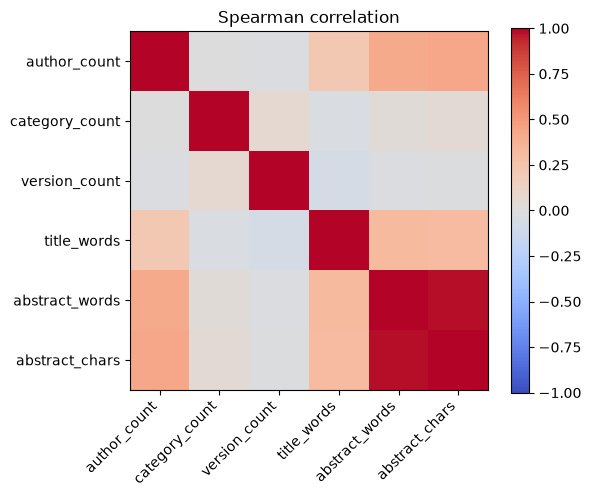

In [12]:
corr = df[num_cols + text_cols].corr(method="spearman")
display(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im)
ax.set_title("Spearman correlation")
plt.tight_layout()
plt.show()